# Pandas: tables, filters, and aggregations

This notebook presents a small, complete workflow with Pandas:
- creating `Series` and `DataFrame` objects;
- selecting columns and rows;
- Boolean filters;
- creating and transforming columns;
- statistics, `groupby`, and handling missing values;
- simple reading and writing without relying on external files.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Creating a Series

In [2]:
grade_series = pd.Series([8.5, 7.0, 9.0], index=["Ana", "Bruno", "Carla"])
print(grade_series)

Ana      8.5
Bruno    7.0
Carla    9.0
dtype: float64


## 2. Creating a DataFrame

In [3]:
df = pd.DataFrame({
    "student": ["Ana", "Bruno", "Carla", "Diego", "Eva"],
    "class_label": ["A", "A", "B", "B", "A"],
    "grade": [8.5, 7.0, 9.0, np.nan, 6.0],
    "absences": [2, 5, 1, 4, 6], 
    })
df

,student,class_label,grade,absences
0,Ana,A,8.5,2
1,Bruno,A,7.0,5
2,Carla,B,9.0,1
3,Diego,B,NaN,4
4,Eva,A,6.0,6


## 3. Selecting columns and rows

In [4]:
print("grade column:")
print(df["grade"])

print("\nRows 0 to 2 with student and grade:")
print(df.loc[0:2, ["student", "grade"]])

print("\nRows 2 onward, from column class_label onward:")
print(df.iloc[2:, 1:])

grade column:
0    8.5
1    7.0
2    9.0
3    NaN
4    6.0
Name: grade, dtype: float64

Rows 0 to 2 with student and grade:
  student  grade
0     Ana    8.5
1   Bruno    7.0
2   Carla    9.0

Rows 2 onward, from column class_label onward:


  class_label  grade  absences
2           B    9.0         1
3           B    NaN         4
4           A    6.0         6


## 4. Boolean filters

In [5]:
passed = df[df["grade"] >= 7.0]
low_attendance = df[df["absences"] > 4]

print("Passed:\n", passed)
print("\nMore than 4 absences:\n", low_attendance)


Passed:
   student class_label  grade  absences
0     Ana           A    8.5         2
1   Bruno           A    7.0         5
2   Carla           B    9.0         1

More than 4 absences:
   student class_label  grade  absences
1   Bruno           A    7.0         5
4     Eva           A    6.0         6


## 5. Handling missing values and creating columns

In [6]:
#mean_grade = df["grade"].mean()

df["grade"] = df["grade"].fillna(mean_grade)
df["status"] = np.where(df["grade"] >= 7.0, "Passed", "Retake")
df["adjusted_grade"] = df["grade"] + 0.5
df["attendance"] = 100 - df["absences"] 
df

,student,class_label,grade,absences,status,adjusted_grade,attendance
0,Ana,A,8.500,2,Passed,9.000,98
1,Bruno,A,7.000,5,Passed,7.500,95
2,Carla,B,9.000,1,Passed,9.500,99
3,Diego,B,7.625,4,Passed,8.125,96
4,Eva,A,6.000,6,Retake,6.500,94


## 6. Statistics and aggregations

In [7]:
#print("Overall mean:", df["grade"].mean())

#print("Highest grade:", df["grade"].max())
print("Numeric summary:\n", df[["grade", "absences", "attendance"]].describe())

Numeric summary:
           grade  absences  attendance
count  5.000000  5.000000    5.000000
mean   7.625000  3.600000   96.400000
std    1.192424  2.073644    2.073644
min    6.000000  1.000000   94.000000
25%    7.000000  2.000000   95.000000
50%    7.625000  4.000000   96.000000
75%    8.500000  5.000000   98.000000
max    9.000000  6.000000   99.000000


## 7. Grouping by class

In [8]:
class_summary = df.groupby("class_label").agg({
    "grade": ["mean", "max"],
    "absences": ["sum", "mean"]
})
class_summary

grade      absences          
                 mean  max      sum      mean
class_label                                  
A            7.166667  8.5       13  4.333333
B            8.312500  9.0        5  2.500000

## 8. Simple reading and writing

In [9]:
# Save the df DataFrame to a CSV file
df.to_csv("data.csv", index=False)

# Read the saved CSV file and store it in df_1
df_1 = pd.read_csv("data.csv")

df_1

,student,class_label,grade,absences,status,adjusted_grade,attendance
0,Ana,A,8.500,2,Passed,9.000,98
1,Bruno,A,7.000,5,Passed,7.500,95
2,Carla,B,9.000,1,Passed,9.500,99
3,Diego,B,7.625,4,Passed,8.125,96
4,Eva,A,6.000,6,Retake,6.500,94


## 9. Complete workflow

We will create a summary table with only the columns most useful for analysis.

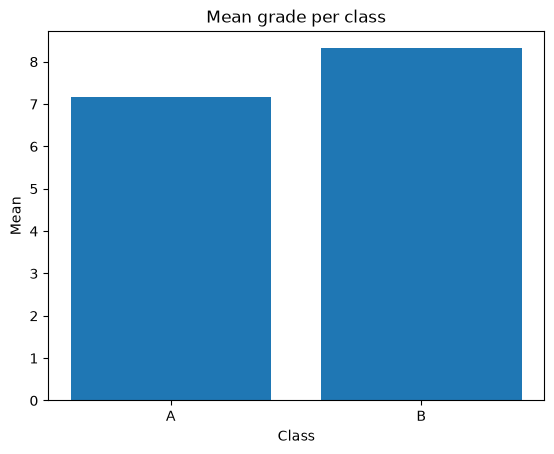

In [10]:
mean_by_class = df.groupby('class_label')['grade'].mean()

plt.bar(mean_by_class.index, mean_by_class.values)
plt.title('Mean grade per class')
plt.xlabel('Class')
plt.ylabel('Mean')
plt.show()

## 10. Using Pandas to obtain a similar result: 

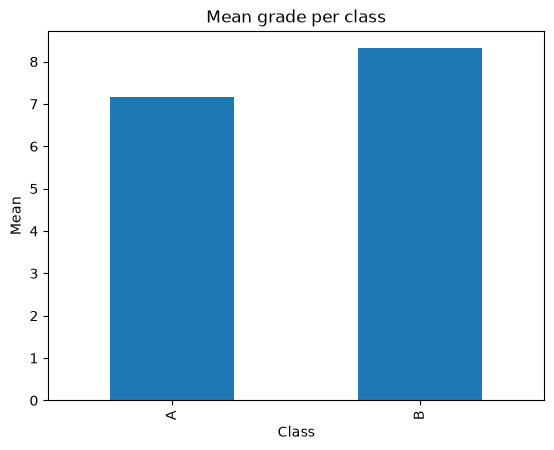

In [11]:
mean_by_class = df.groupby('class_label')['grade'].mean()
mean_by_class.plot(kind='bar')

plt.title('Mean grade per class')
plt.xlabel('Class')
plt.ylabel('Mean')
plt.show()